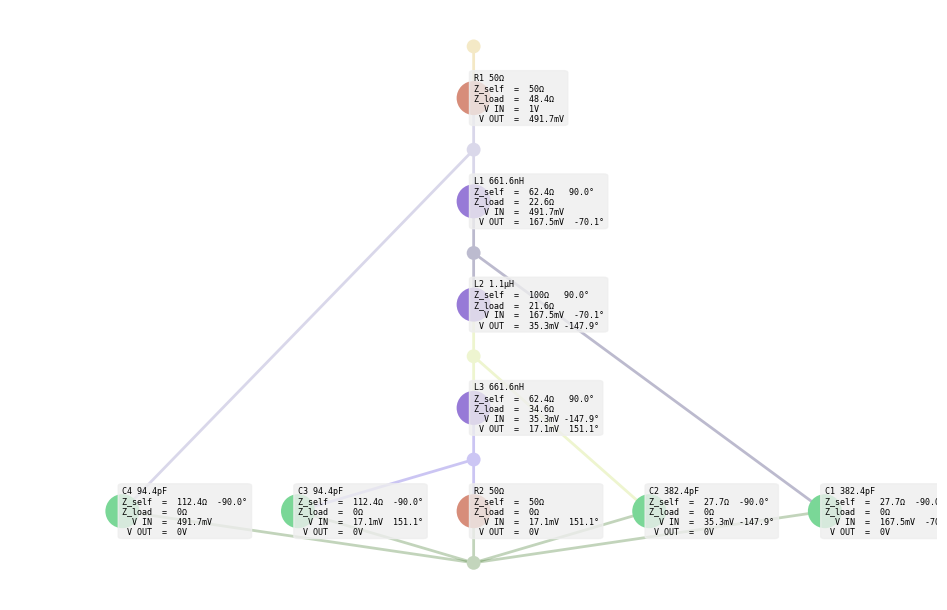

 | Frequency |          Avail P |     Z_load (src) |     Z_src (load) |      V_out (src) |      V_in (load) |   Gain factor | G(ω) dB | 
 | --------- | ---------------- | ---------------- | ---------------- | ---------------- | ---------------- | ------------- | ------- | 
 |     10MHz |              5mW |            49.7Ω |           199.8Ω |          498.3mV |   73.4mV -170.0° |   0.01  19.9° |   -19.7 | 
 |   10.8MHz |              5mW |            49.5Ω |             211Ω |          497.7mV |   58.6mV -177.6° |   0.01   4.7° |   -21.6 | 
 |   11.5MHz |              5mW |            49.4Ω |           222.3Ω |            497mV |   46.9mV  175.5° |   0.00  -9.0° |   -23.6 | 
 |   12.2MHz |              5mW |            49.2Ω |           233.5Ω |          496.1mV |   37.6mV  169.3° |   0.00 -21.5° |   -25.5 | 
 |     13MHz |              5mW |              49Ω |           244.7Ω |          495.1mV |   30.2mV  163.6° |   0.00 -32.7° |   -27.4 | 
 |   13.8MHz |              5mW |        

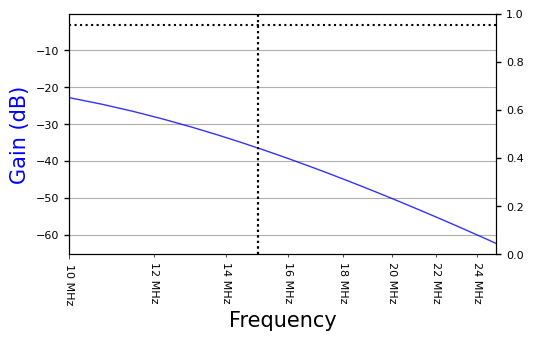

In [3]:
#%load_ext autoreload
#%autoreload 2

import logging
import math
from typing import *
from electrify.ac import impedance, magnitude, phase, phase_angle, to_db, available_power
from electrify.types import *
from electrify.network.nxcompat import to_nx
from electrify.plot.drawcircuit import draw_circuit
from electrify.plot import get_domain
from electrify.plot.bode import BodePlotManager
from electrify.network import fixture, filter
from electrify.network import solve
from electrify.quantity import power
import matplotlib.pyplot as plt
from electrify.value import format_value # mypy:ignore
from table import Table, Column

table = Table([
    #Column('idx',     '#', 5, str),
    Column('f',       'Frequency', 9),
    #Column('p_src',   'Power (src)', 16),
    #Column('p_load',  'Power (load)', 16),
    Column('avail_pwr', 'Avail P', 16),
    #Column('z_src',     'Z_src', 16),
    Column('zs_load', 'Z_load (src)', 16),
    Column('zl_src',  'Z_src (load)', 16),
    Column('vs_out',  'V_out (src)', 16),
    Column('vl_in' ,  'V_in (load)', 16),
    Column('ratio',   'Gain factor', 13, str),
    Column('G',       'G(ω) dB', 7, '{:.1f}'.format),
])


fxt = fixture.TwoPortTestFixture(filter.LowPassFilter(hertz(15e6), 7), ohm(50), ohm(50))
#hpf_test = fixture.TwoPortTestFixture(filter.HighPassFilter(hertz(15e6), 5), ohm(50), ohm(50))

f_min = 10e6
f_max = 25e6
f_target = 15e6 
f_draw_circuit = 15e6
num_samples = 20

solve.logger.setLevel(logging.DEBUG)

#draw_circuit(to_nx(fxt), size=(10,6.5))
draw_circuit(to_nx(fxt), size=(10,6.5), sln=fxt.solution, f=hertz(f_draw_circuit))

d = get_domain(f_min, f_max, num_samples)
fig, ax = plt.subplots()
bpm = BodePlotManager(ax)
bpm.configure(
    d,
    hlines=[-3],
    vlines=[f_target, f_draw_circuit],
    f_min=f_min,
    f_max=f_max,
    size=(5, 3)
)

for i,f in enumerate(d):
    zs_load = fxt.solution.load_impedance(fxt.RS, f, include_self=False)
    zl_src = fxt.solution.source_impedance(fxt.RL, f, include_self=False)
    p_src = fxt.solution.power(fxt.RS, f)
    p_load = fxt.solution.power(fxt.RL, f)
    gf = complex(p_load / p_src)
    gain = float(10 * math.log10(magnitude(gf)))
    
    table.add_row({
        'idx': i,
        'f': hertz(f),
        'avail_pwr': available_power(fxt.solution.volts_in(fxt.RS, f), fxt.RS),
        'p_src': watt(p_src),
        'p_load': watt(p_load),
        'zs_load': zs_load,
        'zl_src': zl_src,
        'vs_out': fxt.solution.volts_out(fxt.RS, f),
        'vl_in': fxt.solution.volts_in(fxt.RL, f),
        'G': gain,
        'ratio': f'{magnitude(gf):6.2f} {phase_angle(gf):5.1f}°',
    })

#bpm.plot_fq([ to_db(hpf_test.transducer_gain(f)) for f in d ], color='blue')
#bpm.plot_fq([ to_db(lpf_test.transducer_gain(f)) for f in d ], color='red')
#bpm.plot_fq([ math.log10(magnitude(lpf_test.power_gain(f)**2)) for f in d ], color="purple")
# bpm.plot_fq([t for t,u,v,w in y], color="orange")
# bpm.plot_ph([w for t,u,v,w in y])

table.print_heading()
table.print_rows()

bpm.plot_fq([to_db(v.real) for v in table.values("vl_in")])
#bpm.plot_fq([ to_db(fxt.voltage_gain(f)) for f in d ], color="orange")
#bpm.plot_fq([ 10.0 * float(math.log10(magnitude(p))) for p in y])
#bpm.plot_ph([ volt(p).phase_angle for p in y])

# bpm.plot_fq([ to_db(lpf_test.insertion_loss(f)) for f in d ], color='blue')
# bpm.plot_fq([ lpf_test.attenuation_factor(f) for f in d ], color='green')
#plt.show()
